### Business objective
LoanTap wants to develop an underwriting model that predicts whether a loan applicant is likely to repay their loan or default.

The model should help LoanTap make two decisions:
- Credit approval: Should the applicant receive a loan?
- Risk management: If approved, what lending terms would be appropriate?
Our machine learning problem is a binary classification problem, because we want to classify borrowers into two outcome groups:

In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv("logistic_regression.csv")

In [4]:
df.shape

(396030, 27)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 396030 entries, 0 to 396029
Data columns (total 27 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   loan_amnt             396030 non-null  float64
 1   term                  396030 non-null  str    
 2   int_rate              396030 non-null  float64
 3   installment           396030 non-null  float64
 4   grade                 396030 non-null  str    
 5   sub_grade             396030 non-null  str    
 6   emp_title             373103 non-null  str    
 7   emp_length            377729 non-null  str    
 8   home_ownership        396030 non-null  str    
 9   annual_inc            396030 non-null  float64
 10  verification_status   396030 non-null  str    
 11  issue_d               396030 non-null  str    
 12  loan_status           396030 non-null  str    
 13  purpose               396030 non-null  str    
 14  title                 394274 non-null  str    
 15  dti        

In [6]:
df.head()

,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,...,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,address
0,10000.0,36 months,11.44,329.48,B,B4,Marketing,10+ years,RENT,117000.0,...,16.0,0.0,36369.0,41.8,25.0,w,INDIVIDUAL,0.0,0.0,"0174 Michelle Gateway\r\nMendozaberg, OK 22690"
1,8000.0,36 months,11.99,265.68,B,B5,Credit analyst,4 years,MORTGAGE,65000.0,...,17.0,0.0,20131.0,53.3,27.0,f,INDIVIDUAL,3.0,0.0,"1076 Carney Fort Apt. 347\r\nLoganmouth, SD 05113"
2,15600.0,36 months,10.49,506.97,B,B3,Statistician,< 1 year,RENT,43057.0,...,13.0,0.0,11987.0,92.2,26.0,f,INDIVIDUAL,0.0,0.0,"87025 Mark Dale Apt. 269\r\nNew Sabrina, WV 05113"
3,7200.0,36 months,6.49,220.65,A,A2,Client Advocate,6 years,RENT,54000.0,...,6.0,0.0,5472.0,21.5,13.0,f,INDIVIDUAL,0.0,0.0,"823 Reid Ford\r\nDelacruzside, MA 00813"
4,24375.0,60 months,17.27,609.33,C,C5,Destiny Management Inc.,9 years,MORTGAGE,55000.0,...,13.0,0.0,24584.0,69.8,43.0,f,INDIVIDUAL,1.0,0.0,"679 Luna Roads\r\nGreggshire, VA 11650"


In [7]:
# Count of each loan status
df['loan_status'].value_counts()

loan_status
Fully Paid     318357
Charged Off     77673
Name: count, dtype: int64

In [8]:
# Percentage distribution
df['loan_status'].value_counts(normalize=True) * 100

loan_status
Fully Paid     80.387092
Charged Off    19.612908
Name: proportion, dtype: float64

<span style="color:brown">Approximately 80% of borrowers have are Fully paid the loan and 20% charged off</span>

<span style="color:brown">The data is imbalanced. The model predicting loan as fully paid is already 80%. So we will have to focus on confusion matrix, precision, recall and ROC-AUC rather than accuracy alone.</span>

### Check for missing values

In [9]:
# Count missing values in each column
missing_count = df.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (df.isnull().mean() * 100).round(2)

# Combine into a DataFrame
missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage': missing_percentage
})

# Display columns containing missing values
missing_df[missing_df['Missing Count'] > 0].sort_values(
    by='Missing Percentage',
    ascending=False
)

,Missing Count,Missing Percentage
mort_acc,37795,9.54
emp_title,22927,5.79
emp_length,18301,4.62
title,1756,0.44
pub_rec_bankruptcies,535,0.14
revol_util,276,0.07


<span style="color:brown">
<ul>
<li>mort_acc has the highest percentage of missing values.</li>
<li> emp_title and emp_length also have missing information.</li>
<li>The remaining columns have relatively few missing values.</li>
<li>We don't have missing values in our target variable, which is good.</li>
</ul></span>

In [10]:
# Dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 396030 entries, 0 to 396029
Data columns (total 27 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   loan_amnt             396030 non-null  float64
 1   term                  396030 non-null  str    
 2   int_rate              396030 non-null  float64
 3   installment           396030 non-null  float64
 4   grade                 396030 non-null  str    
 5   sub_grade             396030 non-null  str    
 6   emp_title             373103 non-null  str    
 7   emp_length            377729 non-null  str    
 8   home_ownership        396030 non-null  str    
 9   annual_inc            396030 non-null  float64
 10  verification_status   396030 non-null  str    
 11  issue_d               396030 non-null  str    
 12  loan_status           396030 non-null  str    
 13  purpose               396030 non-null  str    
 14  title                 394274 non-null  str    
 15  dti        

In [11]:
# Statistical summary of numerical columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
loan_amnt,396030.0,14113.888089,8357.441341,500.00,8000.00,12000.00,20000.00,40000.00
int_rate,396030.0,13.639400,4.472157,5.32,10.49,13.33,16.49,30.99
installment,396030.0,431.849698,250.727790,16.08,250.33,375.43,567.30,1533.81
annual_inc,396030.0,74203.175798,61637.621158,0.00,45000.00,64000.00,90000.00,8706582.00
dti,396030.0,17.379514,18.019092,0.00,11.28,16.91,22.98,9999.00
open_acc,396030.0,11.311153,5.137649,0.00,8.00,10.00,14.00,90.00
pub_rec,396030.0,0.178191,0.530671,0.00,0.00,0.00,0.00,86.00
revol_bal,396030.0,15844.539853,20591.836109,0.00,6025.00,11181.00,19620.00,1743266.00
revol_util,395754.0,53.791749,24.452193,0.00,35.80,54.80,72.90,892.30
total_acc,396030.0,25.414744,11.886991,2.00,17.00,24.00,32.00,151.00


In [12]:
# Number of unique values in each categorical column
cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    print(col, ":", df[col].nunique())

C:\Users\Benita\AppData\Local\Temp\ipykernel_46516\3833428865.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns


term : 2
grade : 7
sub_grade : 35
emp_title : 173105
emp_length : 11
home_ownership : 6
verification_status : 3
issue_d : 115
loan_status : 2
purpose : 14
title : 48816
earliest_cr_line : 684
initial_list_status : 2
application_type : 3
address : 393700


### Univariate Analysis

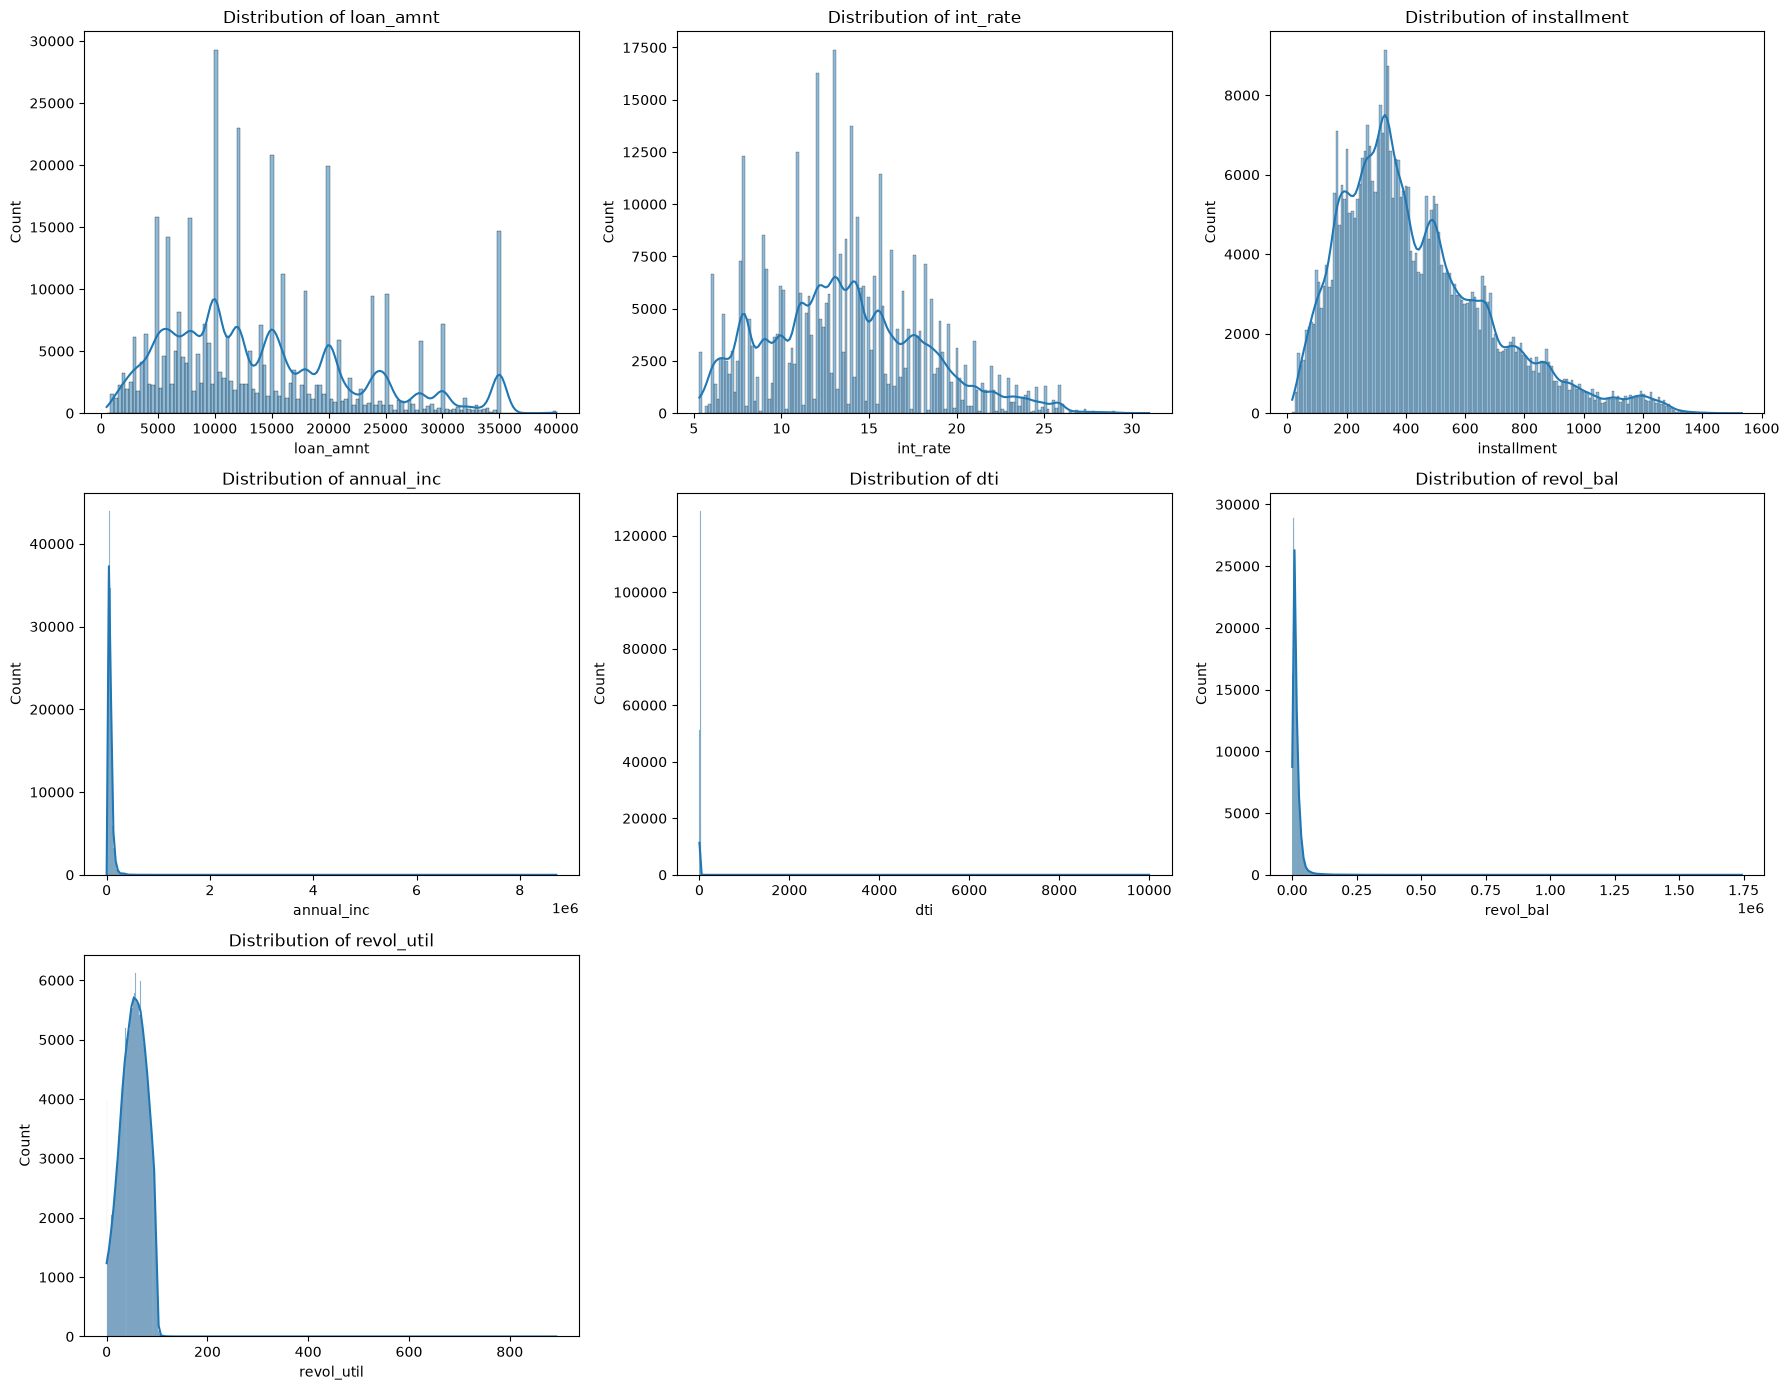

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

continuous_cols = [
    'loan_amnt',
    'int_rate',
    'installment',
    'annual_inc',
    'dti',
    'revol_bal',
    'revol_util'
]

fig, axes = plt.subplots(3, 3, figsize=(18, 14))

axes = axes.flatten()

for i, col in enumerate(continuous_cols):

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f'Distribution of {col}')

# Remove unused subplots
for j in range(len(continuous_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

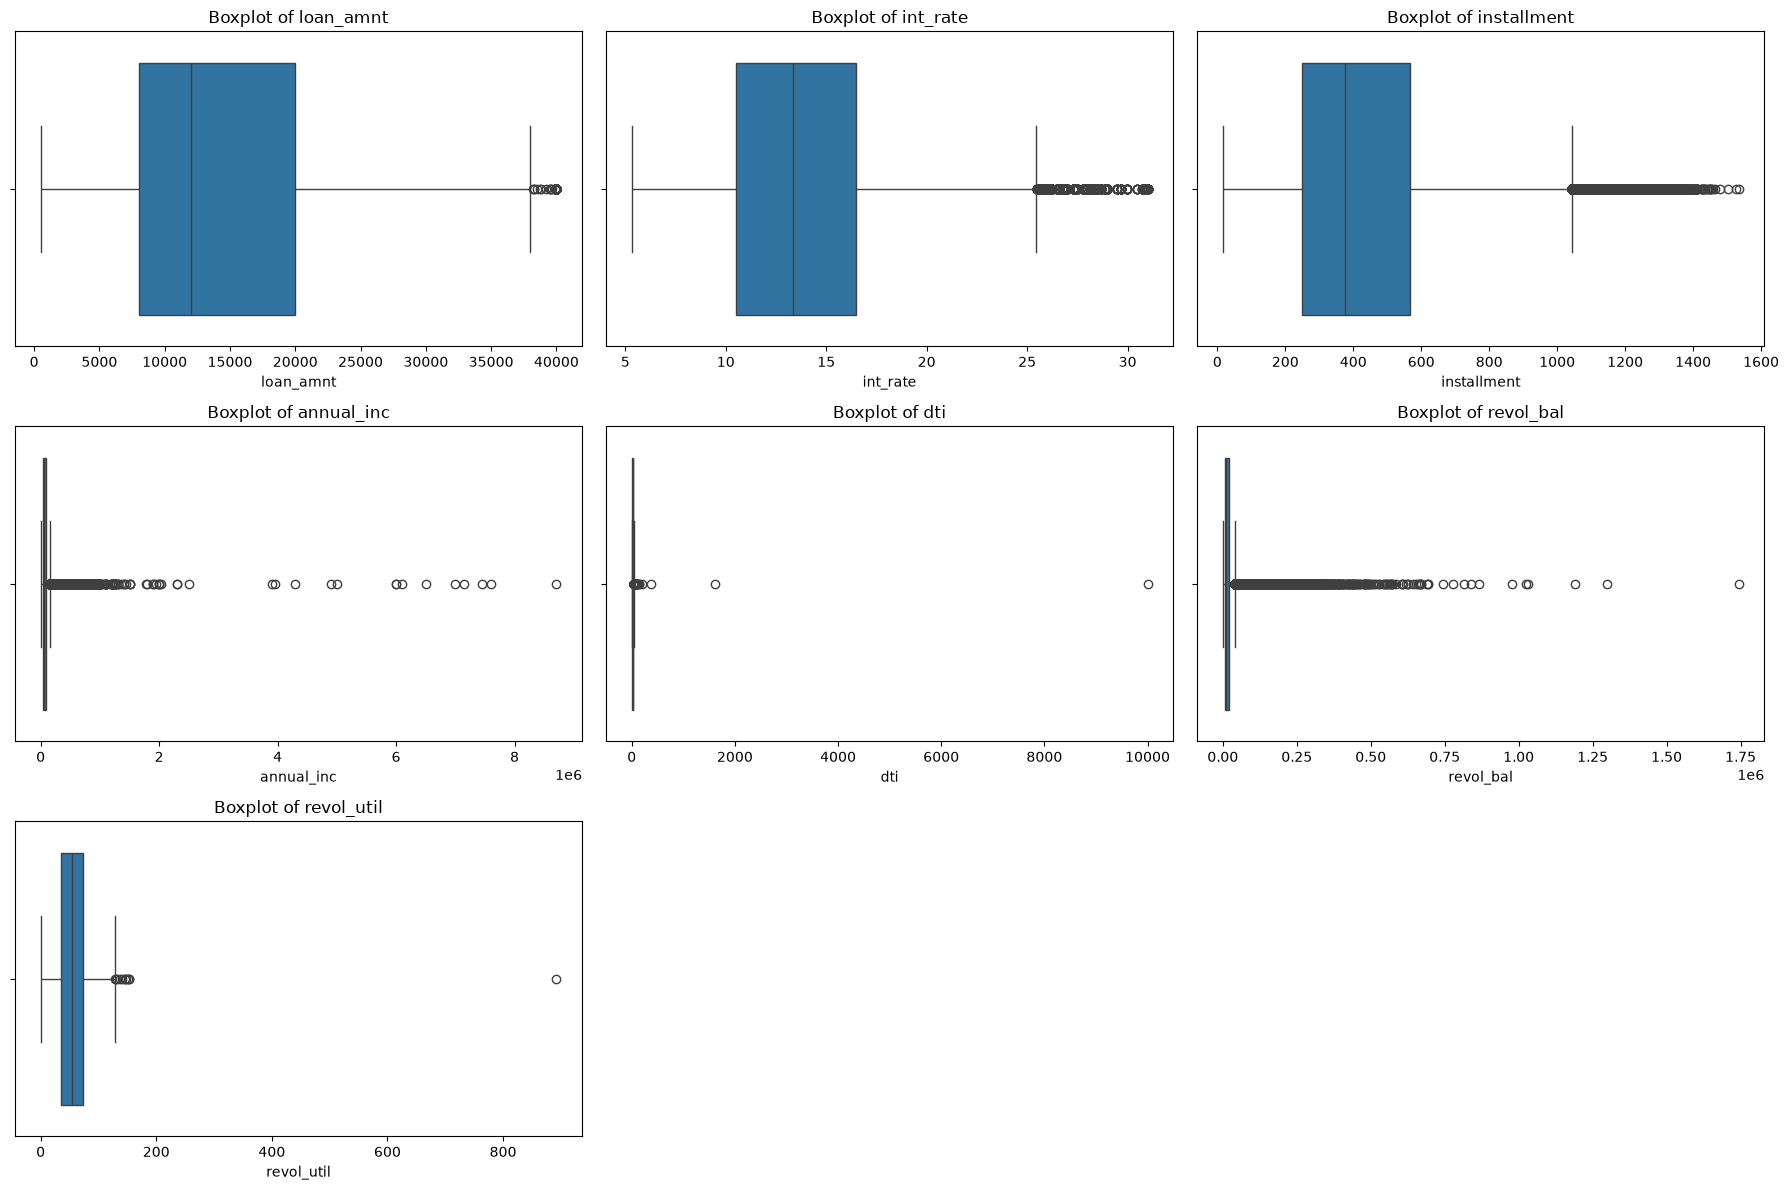

In [14]:
fig, axes = plt.subplots(3, 3, figsize=(18, 12))

axes = axes.flatten()

for i, col in enumerate(continuous_cols):

    sns.boxplot(
        data=df,
        x=col,
        ax=axes[i]
    )

    axes[i].set_title(f'Boxplot of {col}')

for j in range(len(continuous_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [15]:
df[["loan_amnt", "int_rate", "installment", "annual_inc", "dti", "revol_bal", "revol_util"]].describe()

,loan_amnt,int_rate,installment,annual_inc,dti,revol_bal,revol_util
count,396030.000000,396030.000000,396030.000000,3.960300e+05,396030.000000,3.960300e+05,395754.000000
mean,14113.888089,13.639400,431.849698,7.420318e+04,17.379514,1.584454e+04,53.791749
std,8357.441341,4.472157,250.727790,6.163762e+04,18.019092,2.059184e+04,24.452193
min,500.000000,5.320000,16.080000,0.000000e+00,0.000000,0.000000e+00,0.000000
25%,8000.000000,10.490000,250.330000,4.500000e+04,11.280000,6.025000e+03,35.800000
50%,12000.000000,13.330000,375.430000,6.400000e+04,16.910000,1.118100e+04,54.800000
75%,20000.000000,16.490000,567.300000,9.000000e+04,22.980000,1.962000e+04,72.900000
max,40000.000000,30.990000,1533.810000,8.706582e+06,9999.000000,1.743266e+06,892.300000


* Annual income has a maximum of over 8.7 million, compared with a median of 65,000. This suggests a highly dispersed income distribution.
* DTI has a maximum of 9,999. This is an unusual value and deserves investigation.
* Revolving utilization has a maximum of 892.30%. This is unusually high and could represent exceptional credit utilization or a data-quality issue.
* Revolving balance also has a very large maximum compared with its median.

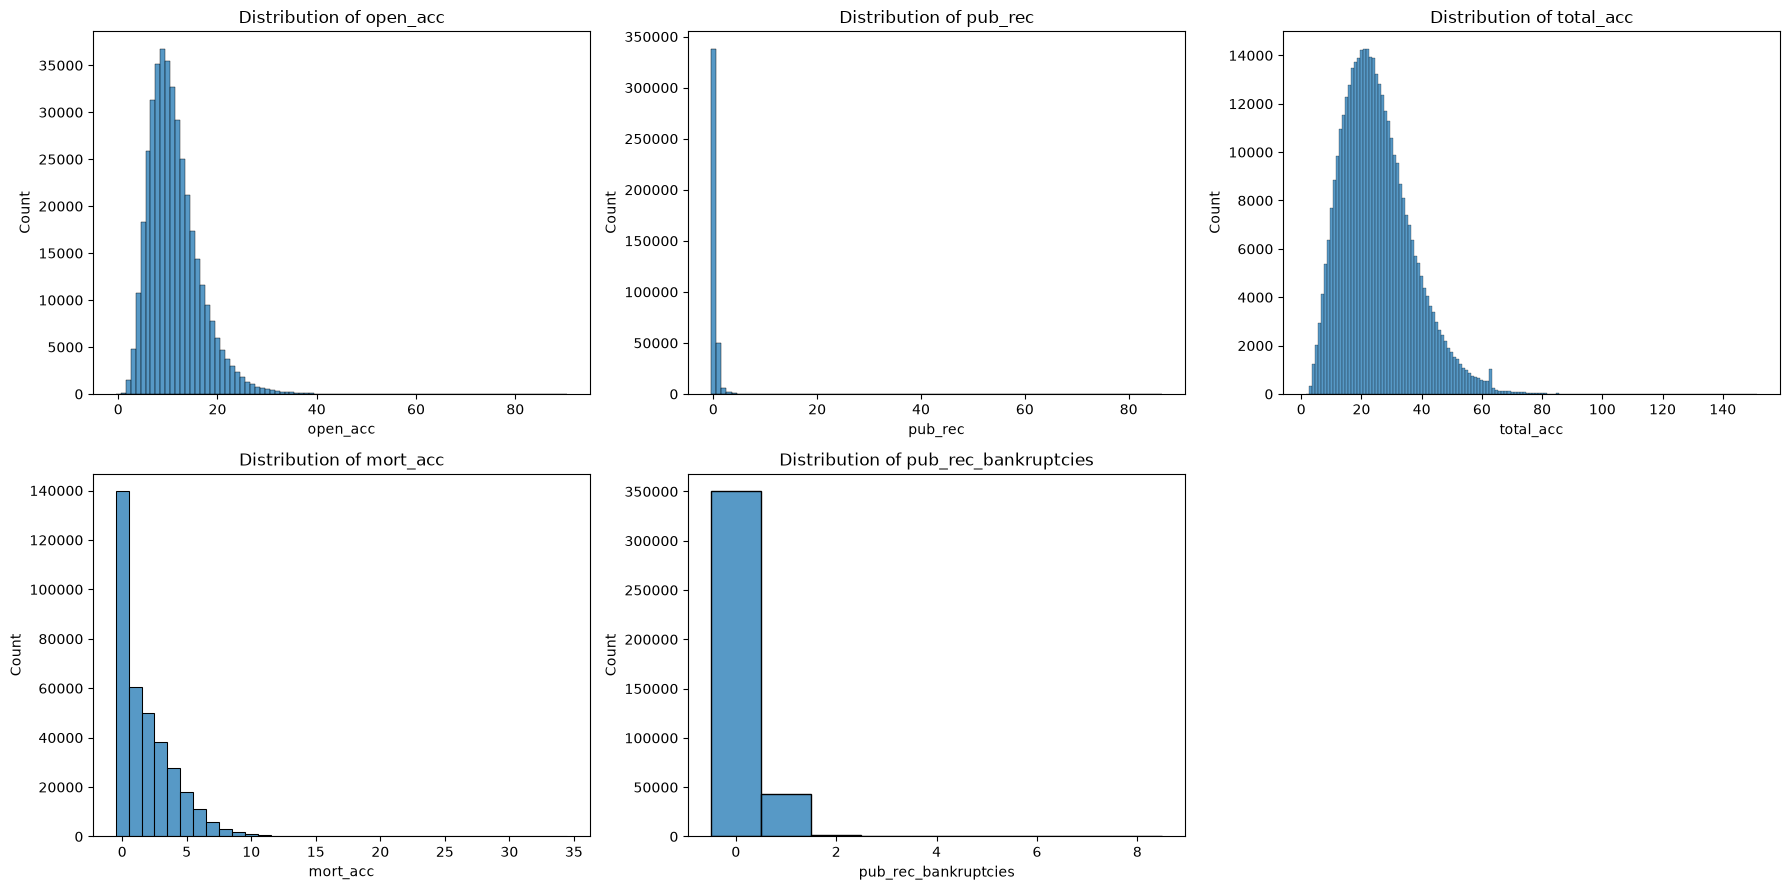

In [16]:
count_cols = [
    'open_acc',
    'pub_rec',
    'total_acc',
    'mort_acc',
    'pub_rec_bankruptcies'
]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))

axes = axes.flatten()

for i, col in enumerate(count_cols):

    sns.histplot(
        data=df,
        x=col,
        discrete=True,
        ax=axes[i]
    )

    axes[i].set_title(f'Distribution of {col}')

for j in range(len(count_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [17]:
# Calculate skewness for continuous variables

df[continuous_cols].skew().sort_values(ascending=False)

dti            431.051225
annual_inc      41.042725
revol_bal       11.727515
installment      0.983598
loan_amnt        0.777285
int_rate         0.420669
revol_util      -0.071778
dtype: float64

### Categorical Variables

In [18]:
categorical_cols = [
    'term',
    'grade',
    'sub_grade',
    'emp_length',
    'home_ownership',
    'verification_status',
    'purpose',
    'initial_list_status',
    'application_type'
]

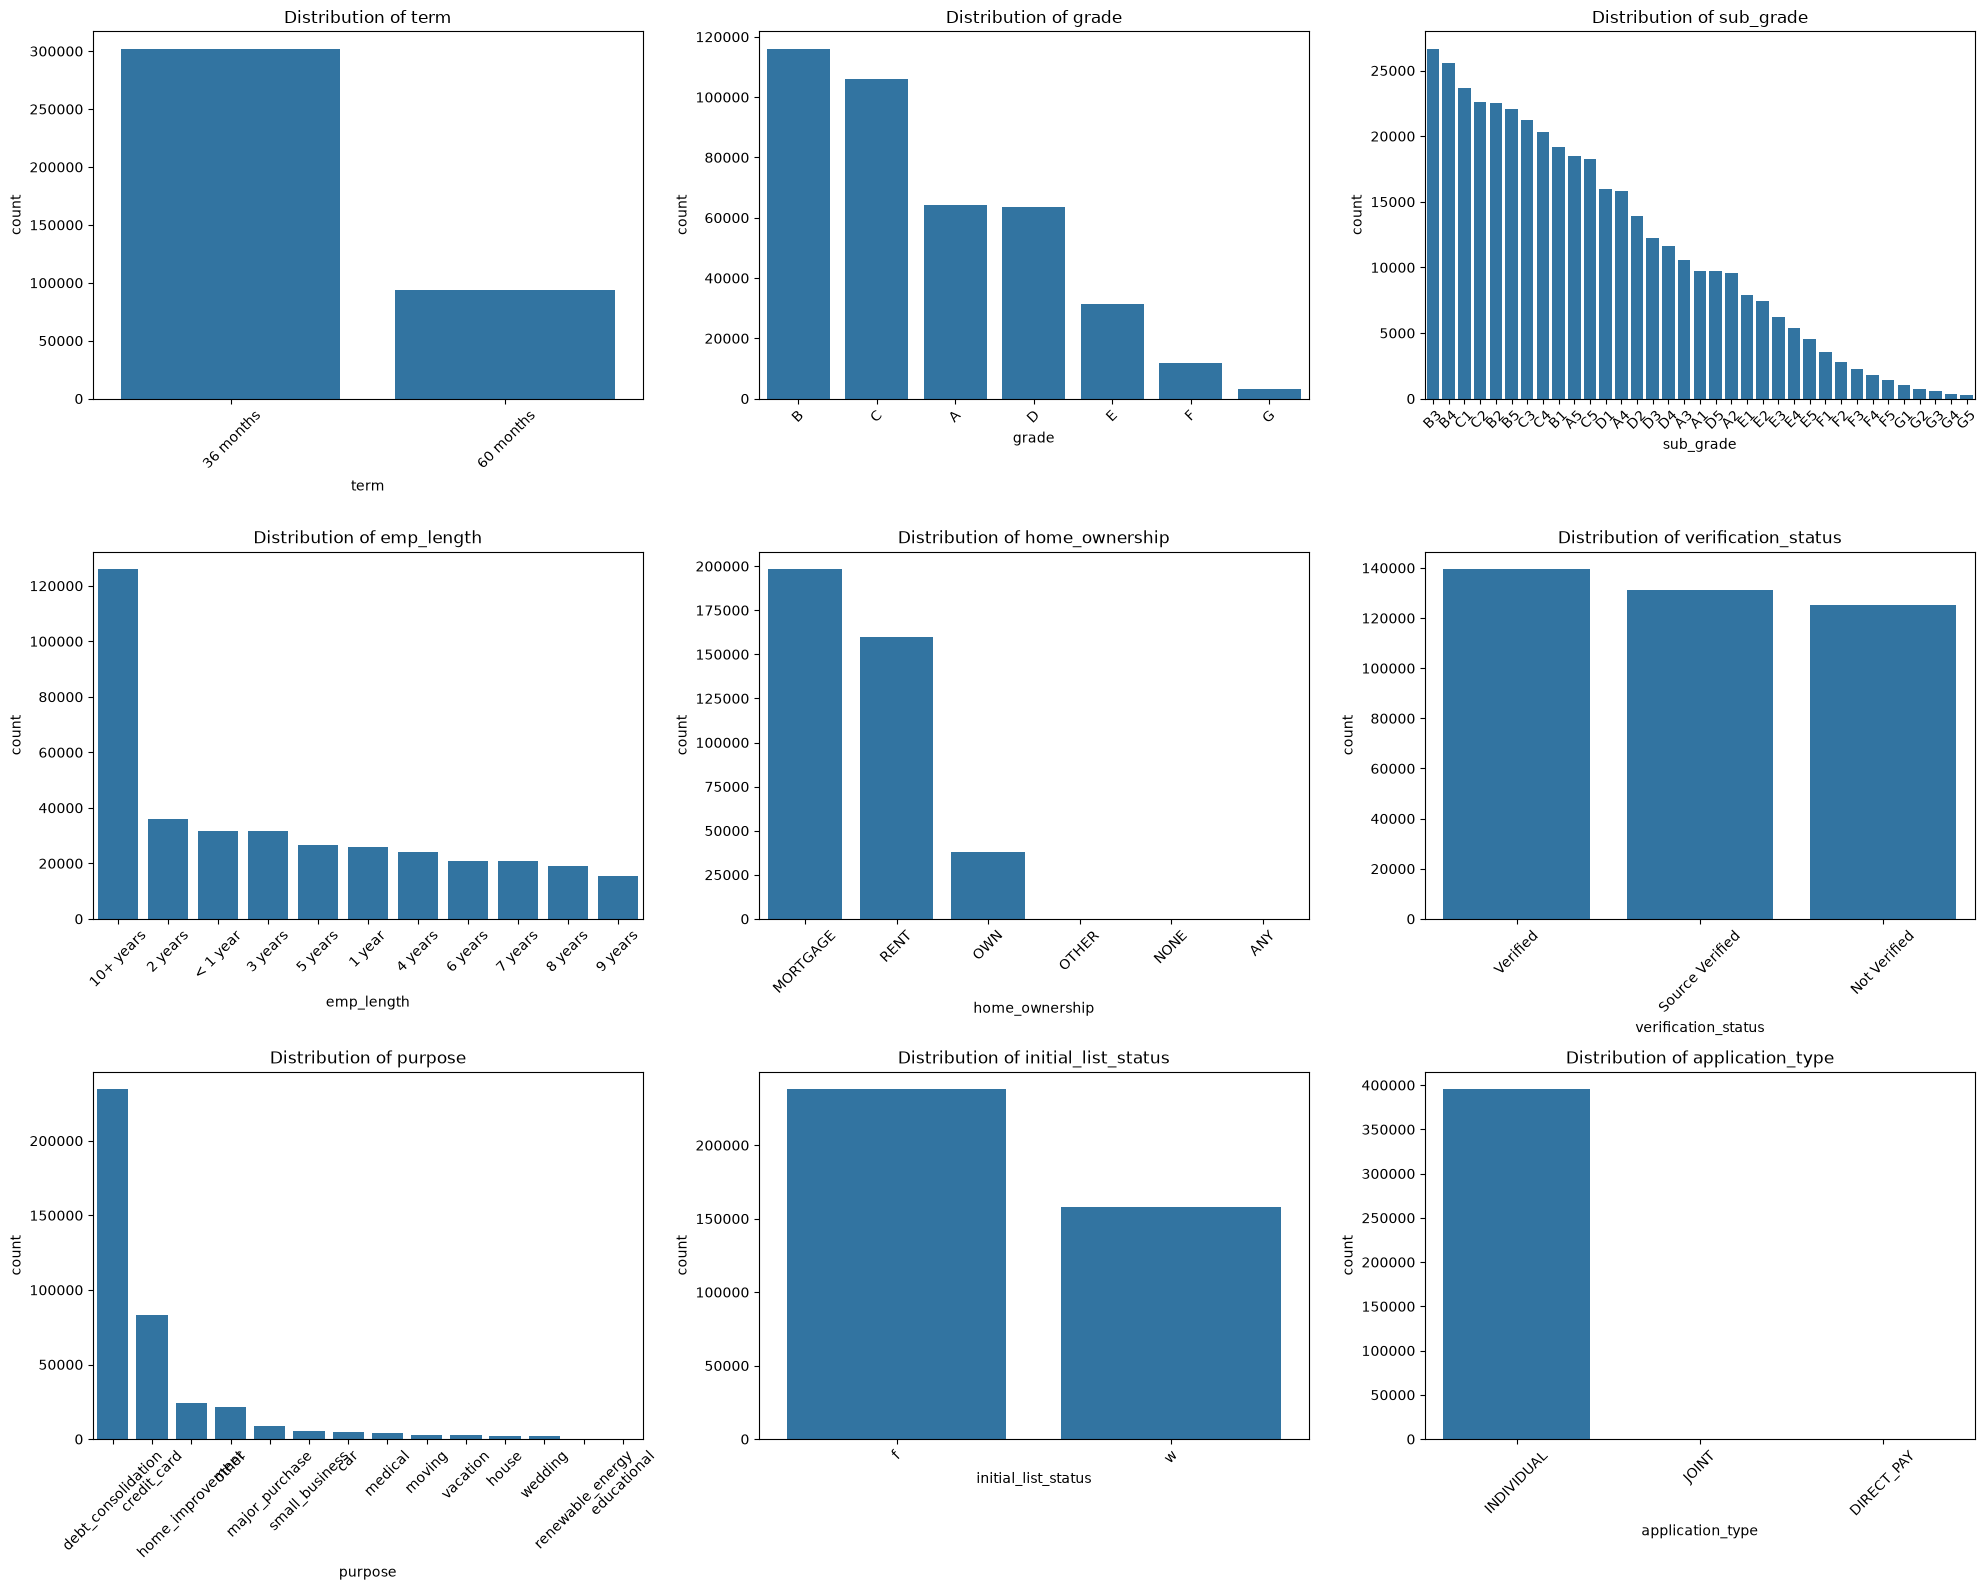

In [19]:
fig, axes = plt.subplots(3, 3, figsize=(20, 16))

axes = axes.flatten()

for i, col in enumerate(categorical_cols):

    sns.countplot(
        data=df,
        x=col,
        ax=axes[i],
        order=df[col].value_counts().index
    )

    axes[i].set_title(f'Distribution of {col}')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

1. Loan term :
    Approximately 76.3% of borrowers have a 36-month loan term.
    This suggests that shorter loan tenures are more common in this dataset.

2. Loan grade :
    Grade B is the most frequent category, followed by grades C and A.
    Loan grades are assigned by LoanTap and represent an assessment of borrower risk.

3. Employment length :
    The largest category is 10+ years.
    This suggests that a substantial proportion of applicants have longer employment histories.

4. Home ownership :
    The majority of borrowers have home ownership as MORTGAGE.
    Approximately 50.1% of the borrowers fall into this category.

5. Verification status :
    Verified income is the most common individual category. However, we should also consider Source Verified as a separate category rather than combining them without justification.

6. Loan purpose :
    Debt consolidation is overwhelmingly the most common loan purpose, followed by credit card repayment.
    This suggests that many borrowers use personal loans to manage or restructure existing debt.

7. Application type :
    Almost all records are individual applications. Joint and direct-pay applications are relatively rare.
    DIRECT_PAY is not necessarily a joint application. We should inspect the dataset's actual values rather than assume that all categories represent the same distinction.

### Bi-variate Analysis

#### Loan grade vs loan status

In [20]:
# Count of loan status for each grade

pd.crosstab(
    df['grade'],
    df['loan_status']
)

loan_status,Charged Off,Fully Paid
grade,,
A,4036,60151
B,14587,101431
C,22449,83538
D,18338,45186
E,11765,19723
F,5037,6735
G,1461,1593


In [21]:
# Percentage distribution within each grade

grade_status = pd.crosstab(
    df['grade'],
    df['loan_status'],
    normalize='index'
) * 100

print(grade_status.round(2))

loan_status  Charged Off  Fully Paid
grade                               
A                   6.29       93.71
B                  12.57       87.43
C                  21.18       78.82
D                  28.87       71.13
E                  37.36       62.64
F                  42.79       57.21
G                  47.84       52.16


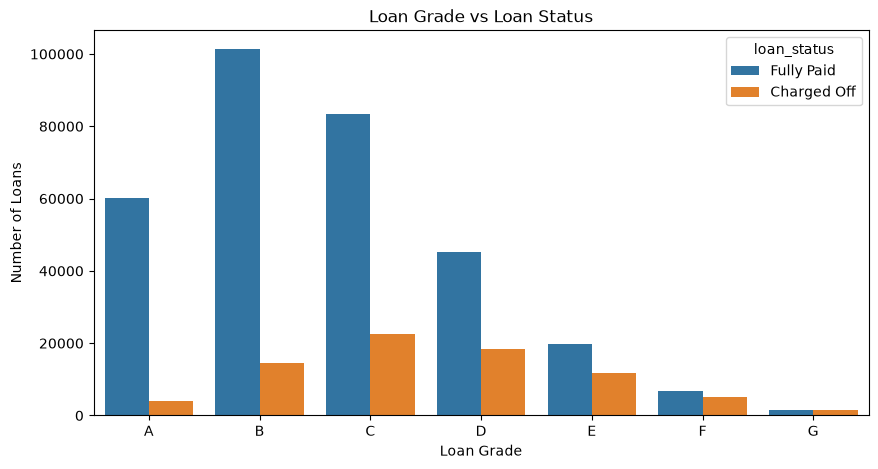

In [22]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='grade',
    hue='loan_status',
    order=sorted(df['grade'].unique())
)

plt.title('Loan Grade vs Loan Status')
plt.xlabel('Loan Grade')
plt.ylabel('Number of Loans')
plt.show()

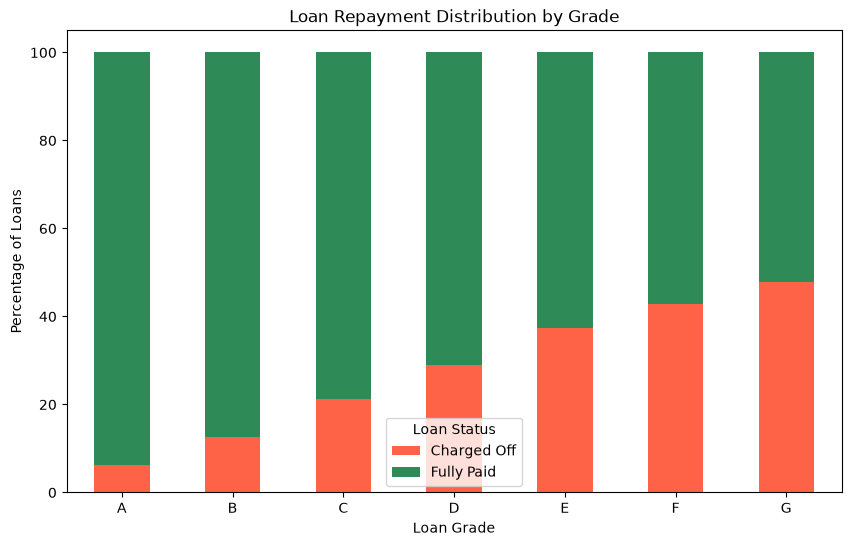

In [23]:
grade_status.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    color=['tomato', 'seagreen']
)

plt.title('Loan Repayment Distribution by Grade')
plt.xlabel('Loan Grade')
plt.ylabel('Percentage of Loans')
plt.xticks(rotation=0)
plt.legend(title='Loan Status')
plt.show()

As the loan grade moves from A to G:
- The percentage of fully paid loans decreases.
- The percentage of charged-off loans increases.

People with grades A are more likely to fully pay their loan.
Evidence: 93.71% of Grade A loans were fully paid, compared with 52.16% of Grade G loans.

#### Interest Rate vs. Loan Status

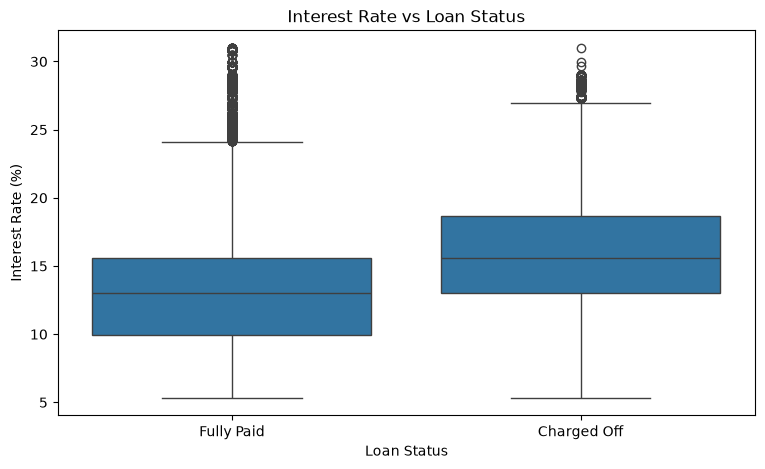

In [24]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='loan_status',
    y='int_rate'
)

plt.title('Interest Rate vs Loan Status')
plt.xlabel('Loan Status')
plt.ylabel('Interest Rate (%)')

plt.show()

In [25]:
df.groupby('loan_status')['int_rate'].agg(
    ['mean', 'median', 'min', 'max']
).round(2)

,mean,median,min,max
loan_status,,,,
Charged Off,15.88,15.61,5.32,30.99
Fully Paid,13.09,12.99,5.32,30.99


Borrowers whose loans were Charged Off have a mean interest rate of 15.88%, compared with 13.09% for Fully Paid borrowers.

The median interest rate for Charged Off borrowers is 15.61%, compared with 12.99% for Fully Paid borrowers.

The difference in mean interest rates is 2.79 percentage points.

#### Loan Amount vs Installment

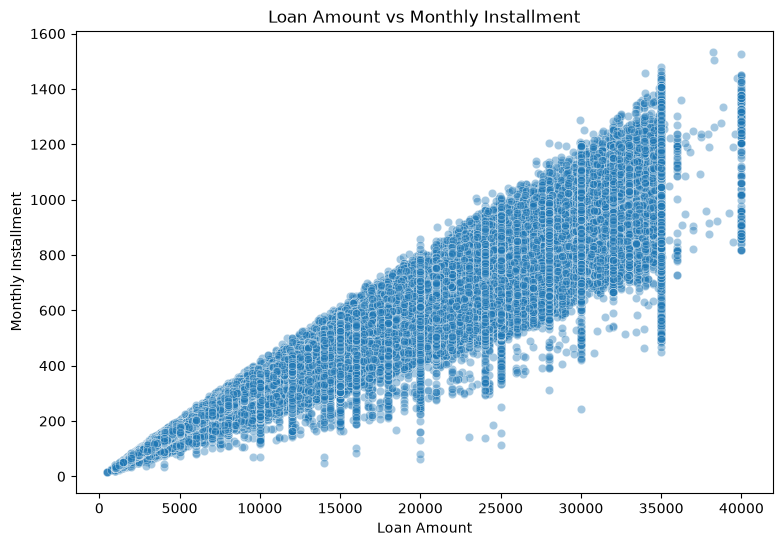

In [26]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df, #.sample(5000, random_state=42),
    x='loan_amnt',
    y='installment',
    alpha=0.4
)

plt.title('Loan Amount vs Monthly Installment')
plt.xlabel('Loan Amount')
plt.ylabel('Monthly Installment')

plt.show()

In [27]:
df[['loan_amnt', 'installment']].corr()

,loan_amnt,installment
loan_amnt,1.000000,0.953929
installment,0.953929,1.000000


Scatterplot and correlation value show a very strong positive linear relationship between loan amount and monthly installment.

Because these two features are highly correlated, including both in Logistic Regression could contribute to multicollinearity

#### Annual Income vs Loan Status

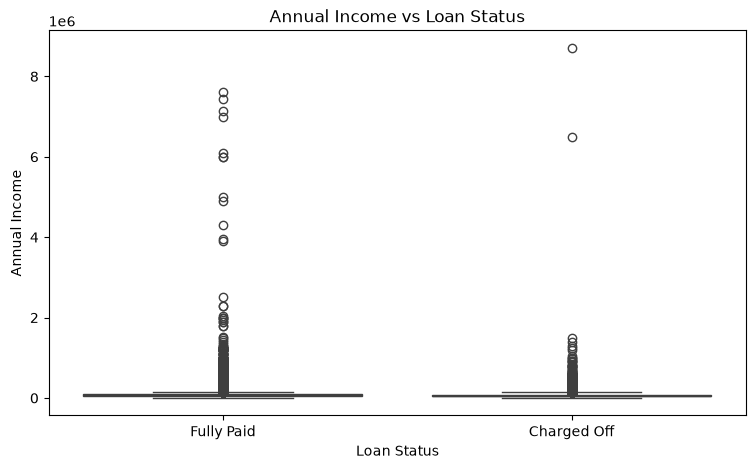

In [28]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='loan_status',
    y='annual_inc'
)

plt.title('Annual Income vs Loan Status')
plt.xlabel('Loan Status')
plt.ylabel('Annual Income')
plt.show()

In [29]:
df.groupby('loan_status')['annual_inc'].agg(
    ['mean', 'median', 'min', 'max']
).round(2)

,mean,median,min,max
loan_status,,,,
Charged Off,67535.54,59000.0,0.0,8706582.0
Fully Paid,75829.95,65000.0,600.0,7600000.0


Median income: Fully Paid borrowers have a median annual income of $65,000, compared with $59,000 for Charged Off borrowers. This suggests that borrowers with higher typical incomes may be more likely to repay their loans.

Mean income: The mean is also higher for Fully Paid borrowers. However, extremely high incomes pull the averages upwards.

Since annual income is highly right-skewed, let's use a logarithmic transformation for visualisation. This will make the central distributions easier to compare.

Note: log1p() calculates log(1 + income), allowing us to handle zero-income observations without getting an undefined logarithm.

This is only a visualisation transformation for now; original income column is not changed

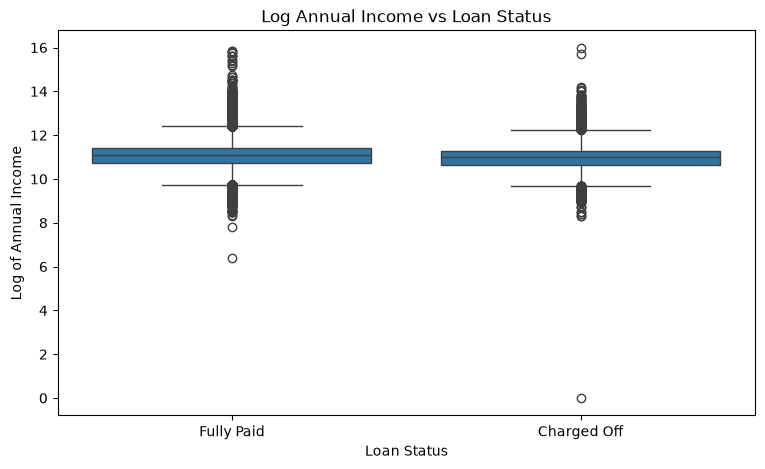

In [30]:
df['log_annual_inc'] = np.log1p(df['annual_inc'])

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='loan_status',
    y='log_annual_inc'
)

plt.title('Log Annual Income vs Loan Status')
plt.xlabel('Loan Status')
plt.ylabel('Log of Annual Income')
plt.show()

#### DTI vs. loan status

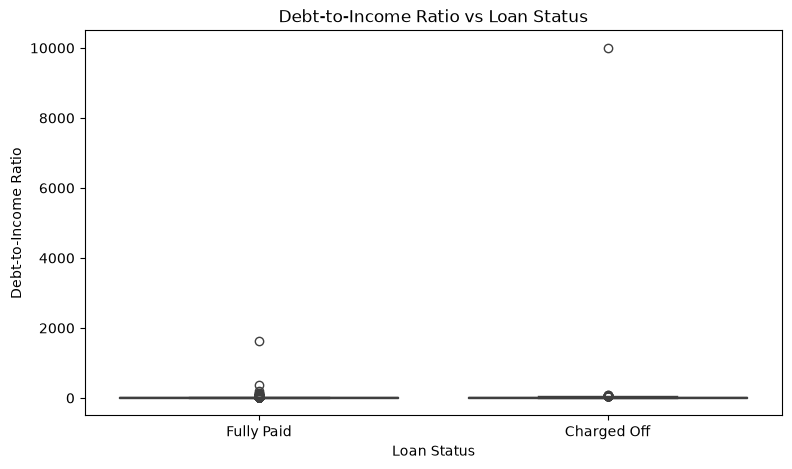

In [31]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='loan_status',
    y='dti'
)

plt.title('Debt-to-Income Ratio vs Loan Status')
plt.xlabel('Loan Status')
plt.ylabel('Debt-to-Income Ratio')
plt.show()

In [32]:
df.groupby('loan_status')['dti'].agg(
    ['mean', 'median', 'min', 'max']
).round(2)

,mean,median,min,max
loan_status,,,,
Charged Off,19.66,19.34,0.0,9999.0
Fully Paid,16.82,16.34,0.0,1622.0


Median: Charged Off borrowers have a median DTI of 19.34, compared with 16.34 for Fully Paid borrowers.

Mean: The average DTI is also higher for Charged Off borrowers (19.66 vs 16.82).

Outliers: The maximum DTI of 9,999 is extremely unusual. The maximum of 1,622 in the Fully Paid group is also worth investigating.

Potential risk indicator: Borrowers with higher DTI may have a greater repayment burden relative to their income, which could be associated with a higher probability of default.

Check for extreme DTI values

In [33]:
df['dti'].describe(percentiles=[0.90, 0.95, 0.99, 0.999])

count    396030.000000
mean         17.379514
std          18.019092
min           0.000000
90%          28.500000
95%          31.580000
99%          36.430000
99.9%        39.860000
max        9999.000000
Name: dti, dtype: float64

99% of observations have DTI at or below 36.43.
99.9% have DTI at or below 39.86.
Maximum of 9999 is extraordinarily far from the rest of the distribution

In [34]:
df[df['dti'] > 100][
    ['dti', 'annual_inc', 'loan_amnt', 'loan_status']
].sort_values('dti', ascending=False).head(10)

,dti,annual_inc,loan_amnt,loan_status
285674,9999.00,0.0,3700.0,Charged Off
350865,1622.00,600.0,24000.0,Fully Paid
338571,380.53,5000.0,19000.0,Fully Paid
7011,189.90,2500.0,18375.0,Fully Paid
36015,145.65,8000.0,15100.0,Fully Paid
296164,138.03,16000.0,14000.0,Fully Paid
294182,120.66,8700.0,15000.0,Fully Paid
264045,107.55,6672.0,3200.0,Fully Paid


The record with DTI = 9,999 has annual income = 0 and loan amount = $3,700.


In [35]:
dti_limits = [40, 50, 100, 500, 1000]

for limit in dti_limits:
    count = (df['dti'] > limit).sum()
    percentage = count / len(df) * 100

    print(
        f"DTI > {limit}: {count} records ({percentage:.4f}%)"
    )

DTI > 40: 296 records (0.0747%)
DTI > 50: 35 records (0.0088%)
DTI > 100: 8 records (0.0020%)
DTI > 500: 2 records (0.0005%)
DTI > 1000: 2 records (0.0005%)


These counts tell us that the extreme DTI observations are very few. Out of 396,030 records, only 296 (0.075%) have DTI above 40.

### Revolving Credit Utilisation vs Loan Status

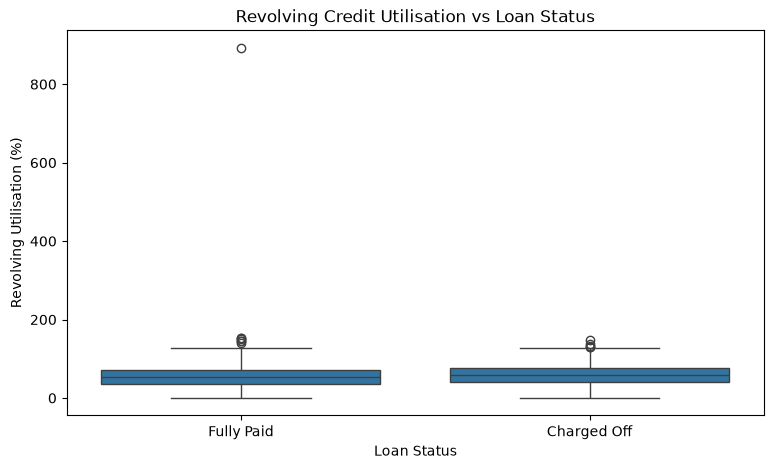

In [36]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='loan_status',
    y='revol_util'
)

plt.title('Revolving Credit Utilisation vs Loan Status')
plt.xlabel('Loan Status')
plt.ylabel('Revolving Utilisation (%)')
plt.show()

In [37]:
df.groupby('loan_status')['revol_util'].agg(
    ['mean', 'median', 'min', 'max']
).round(2)

,mean,median,min,max
loan_status,,,,
Charged Off,57.87,59.3,0.0,148.0
Fully Paid,52.80,53.7,0.0,892.3


Median: Charged Off borrowers have a median utilisation of 59.3%, compared with 53.7% for Fully Paid borrowers.

Mean: The average is also higher for Charged Off borrowers.

Outliers: Both groups contain values above 100%. The maximum of 892.3% in the Fully Paid group is particularly unusual.

Potential risk indicator: Higher credit utilisation may indicate that borrowers are relying more heavily on their available credit, potentially increasing repayment pressure.

### Home Ownership vs Loan Status

In [38]:
home_status = pd.crosstab(
    df['home_ownership'],
    df['loan_status'],
    normalize='index'
) * 100

print(home_status.round(2))

loan_status     Charged Off  Fully Paid
home_ownership                         
ANY                    0.00      100.00
MORTGAGE              16.96       83.04
NONE                  22.58       77.42
OTHER                 14.29       85.71
OWN                   20.68       79.32
RENT                  22.66       77.34


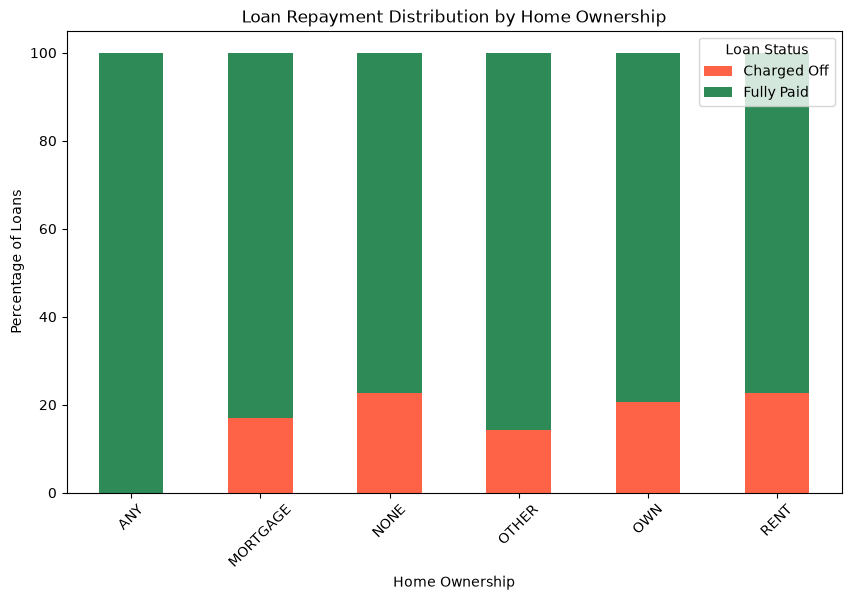

In [39]:
home_status.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    color=['tomato', 'seagreen']
)

plt.title('Loan Repayment Distribution by Home Ownership')
plt.xlabel('Home Ownership')
plt.ylabel('Percentage of Loans')
plt.xticks(rotation=45)
plt.legend(title='Loan Status')
plt.show()

Median: Charged Off borrowers have a median utilisation of 59.3%, compared with 53.7% for Fully Paid borrowers.

Mean: The average is also higher for Charged Off borrowers.

Outliers: Both groups contain values above 100%. The maximum of 892.3% in the Fully Paid group is particularly unusual.

Potential risk indicator: Higher credit utilisation may indicate that borrowers are relying more heavily on their available credit, potentially increasing repayment pressure.

In [40]:
df['home_ownership'].value_counts()

home_ownership
MORTGAGE    198348
RENT        159790
OWN          37746
OTHER          112
NONE            31
ANY              3
Name: count, dtype: int64

### Loan Purpose vs Loan Status

In [41]:
purpose_status = pd.crosstab(
    df['purpose'],
    df['loan_status'],
    normalize='index'
) * 100

print(purpose_status.round(2).sort_values(by='Charged Off', ascending=False))

loan_status         Charged Off  Fully Paid
purpose                                    
small_business            29.45       70.55
moving                    23.48       76.52
renewable_energy          23.40       76.60
medical                   21.71       78.29
other                     21.22       78.78
debt_consolidation        20.74       79.26
house                     19.72       80.28
vacation                  18.92       81.08
home_improvement          17.01       82.99
credit_card               16.71       83.29
major_purchase            16.47       83.53
educational               16.34       83.66
car                       13.48       86.52
wedding                   12.09       87.91


1. Small business: Has the highest charged-off percentage at 29.45%. This may indicate that loans taken for small businesses carry additional repayment uncertainty.
2. Moving and renewable energy: Both have charged-off percentages above 23%.
3. Wedding: Has the lowest charged-off percentage at 12.09%.
4. Debt consolidation: Although it represents a large proportion of the dataset, its charged-off percentage is 20.74%.
5. Car loans: Have a relatively low charged-off percentage of 13.48%.

In [42]:
df['purpose'].value_counts()

purpose
debt_consolidation    234507
credit_card            83019
home_improvement       24030
other                  21185
major_purchase          8790
small_business          5701
car                     4697
medical                 4196
moving                  2854
vacation                2452
house                   2201
wedding                 1812
renewable_energy         329
educational              257
Name: count, dtype: int64

Debt consolidation dominates: Approximately 59.2% of all loans are for debt consolidation.

Small business: Although its sample size is reasonably substantial (5,701), it has the highest charged-off percentage. 

Renewable energy and educational: These have only 329 and 257 records, respectively. Their percentages should be interpreted cautiously.

Wedding: Has a relatively low charged-off percentage, based on 1,812 records.

### Employment Length vs Loan Status

In [43]:
emp_status = pd.crosstab(
    df['emp_length'],
    df['loan_status'],
    normalize='index'
) * 100

print(emp_status.round(2))

loan_status  Charged Off  Fully Paid
emp_length                          
1 year             19.91       80.09
10+ years          18.42       81.58
2 years            19.33       80.67
3 years            19.52       80.48
4 years            19.24       80.76
5 years            19.22       80.78
6 years            18.92       81.08
7 years            19.48       80.52
8 years            19.98       80.02
9 years            20.05       79.95
< 1 year           20.69       79.31


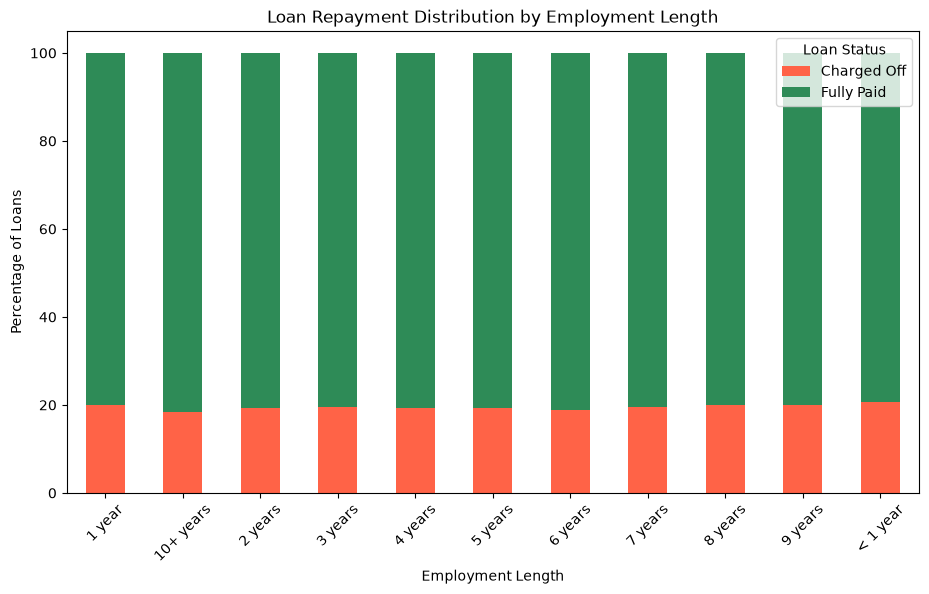

In [44]:
emp_status.plot(
    kind='bar',
    stacked=True,
    figsize=(11, 6),
    color=['tomato', 'seagreen']
)

plt.title('Loan Repayment Distribution by Employment Length')
plt.xlabel('Employment Length')
plt.ylabel('Percentage of Loans')
plt.xticks(rotation=45)
plt.legend(title='Loan Status')
plt.show()

Highest default rate: Less than 1 year of employment (20.69%).

Lowest default rate: 10+ years of employment (18.42%).

Borrowers with 10+ years of employment have a somewhat lower charged-off percentage.

However, the differences are relatively small, and the pattern is not consistently decreasing as employment length increases.

### Correlation analysis of numerical features

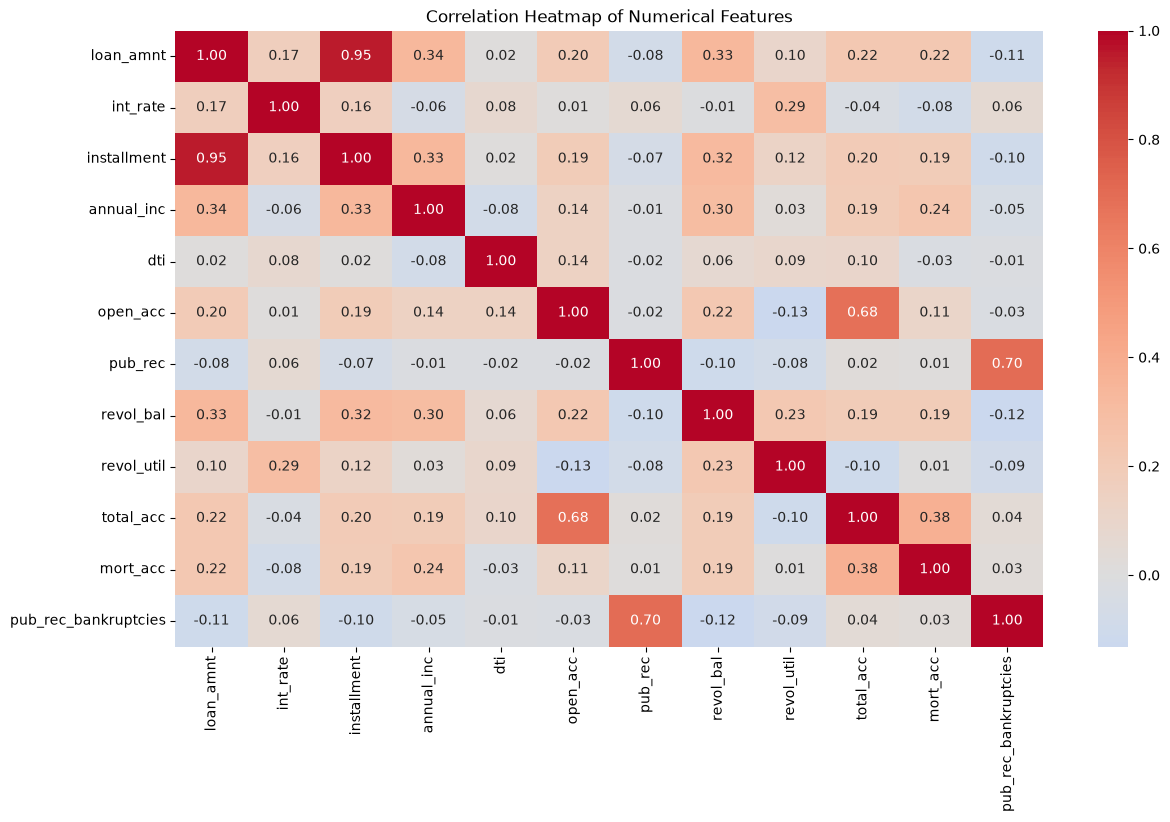

In [45]:
numeric_cols = [
    'loan_amnt',
    'int_rate',
    'installment',
    'annual_inc',
    'dti',
    'open_acc',
    'pub_rec',
    'revol_bal',
    'revol_util',
    'total_acc',
    'mort_acc',
    'pub_rec_bankruptcies'
]

corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(14, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Correlation Heatmap of Numerical Features')
plt.show()

### Correlation Analysis of Numerical Features

A correlation analysis was performed to identify relationships among numerical variables and investigate potential multicollinearity.

The following highly correlated pairs were identified:

| Feature Pair | Correlation |
|---|---:|
| loan_amnt and installment | 0.9539 |
| pub_rec and pub_rec_bankruptcies | 0.6994 |
| open_acc and total_acc | 0.6807 |

The strongest relationship was observed between loan amount and installment, indicating substantial overlap in the information captured by these variables.

Other moderately correlated relationships included loan amount and annual income (0.3369), installment and annual income (0.3304), and total accounts and mortgage accounts (0.3811).

**Inference:** Potential multicollinearity exists among some numerical predictors. These relationships will be investigated further during feature selection and VIF analysis. Highly correlated features will not be removed automatically, as their individual predictive value and business relevance must also be considered.

In [46]:
corr_matrix

,loan_amnt,int_rate,installment,annual_inc,dti,open_acc,pub_rec,revol_bal,revol_util,total_acc,mort_acc,pub_rec_bankruptcies
loan_amnt,1.000000,0.168921,0.953929,0.336887,0.016636,0.198556,-0.077779,0.328320,0.099911,0.223886,0.222315,-0.106539
int_rate,0.168921,1.000000,0.162758,-0.056771,0.079038,0.011649,0.060986,-0.011280,0.293659,-0.036404,-0.082583,0.057450
installment,0.953929,0.162758,1.000000,0.330381,0.015786,0.188973,-0.067892,0.316455,0.123915,0.202430,0.193694,-0.098628
annual_inc,0.336887,-0.056771,0.330381,1.000000,-0.081685,0.136150,-0.013720,0.299773,0.027871,0.193023,0.236320,-0.050162
dti,0.016636,0.079038,0.015786,-0.081685,1.000000,0.136181,-0.017639,0.063571,0.088375,0.102128,-0.025439,-0.014558
open_acc,0.198556,0.011649,0.188973,0.136150,0.136181,1.000000,-0.018392,0.221192,-0.131420,0.680728,0.109205,-0.027732
pub_rec,-0.077779,0.060986,-0.067892,-0.013720,-0.017639,-0.018392,1.000000,-0.101664,-0.075910,0.019723,0.011552,0.699408
revol_bal,0.328320,-0.011280,0.316455,0.299773,0.063571,0.221192,-0.101664,1.000000,0.226346,0.191616,0.194925,-0.124532
revol_util,0.099911,0.293659,0.123915,0.027871,0.088375,-0.131420,-0.075910,0.226346,1.000000,-0.104273,0.007514,-0.086751
total_acc,0.223886,-0.036404,0.202430,0.193023,0.102128,0.680728,0.019723,0.191616,-0.104273,1.000000,0.381072,0.042035


In [47]:
categorical_cols = df.select_dtypes(
    include=['object']
).columns

for col in categorical_cols:
    print(
        f"{col}: {df[col].nunique()} unique values"
    )

C:\Users\Benita\AppData\Local\Temp\ipykernel_46516\2342625190.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(


term: 2 unique values
grade: 7 unique values
sub_grade: 35 unique values
emp_title: 173105 unique values
emp_length: 11 unique values
home_ownership: 6 unique values
verification_status: 3 unique values
issue_d: 115 unique values
loan_status: 2 unique values
purpose: 14 unique values
title: 48816 unique values
earliest_cr_line: 684 unique values
initial_list_status: 2 unique values
application_type: 3 unique values
address: 393700 unique values


### Categorical Feature Cardinality Analysis

The categorical variables were examined to identify their unique-value counts and determine appropriate encoding strategies.

**Low-cardinality features:** Variables such as term, grade, emp_length, home_ownership, verification_status, purpose, initial_list_status and application_type have a manageable number of categories and are candidates for One-Hot Encoding.

**High-cardinality features:** emp_title (173,105 unique values), title (48,816 unique values) and address (393,700 unique values) have very high cardinality. Direct One-Hot Encoding would create a large number of features and increase model complexity. These variables will be excluded from the initial model or investigated for meaningful aggregation.

**Date features:** issue_d and earliest_cr_line will be converted into date formats and examined for feature engineering opportunities, such as loan issue period and credit history length.

**Target variable:** loan_status will be converted into a binary variable, with Charged Off represented as 1 and Fully Paid as 0.

**Inference:** Appropriate encoding and feature engineering are essential to prepare the dataset for Logistic Regression while controlling dimensionality and avoiding unnecessary model complexity.

## Missing-value analysis

In [48]:
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (
        df.isnull().sum() / len(df)
    ) * 100
})

missing = missing[missing['Missing_Count'] > 0]

missing = missing.sort_values(
    by='Missing_Percentage',
    ascending=False
)

print(missing.round(2))

                      Missing_Count  Missing_Percentage
mort_acc                      37795                9.54
emp_title                     22927                5.79
emp_length                    18301                4.62
title                          1756                0.44
pub_rec_bankruptcies            535                0.14
revol_util                      276                0.07


Missing values were identified in six features.

| Feature | Missing Count | Missing Percentage |
|---|---:|---:|
| mort_acc | 37,795 | 9.54% |
| emp_title | 22,927 | 5.79% |
| emp_length | 18,301 | 4.62% |
| title | 1,756 | 0.44% |
| pub_rec_bankruptcies | 535 | 0.14% |
| revol_util | 276 | 0.07% |

The highest proportion of missing values was observed in mort_acc, followed by emp_title and emp_length.

**Preliminary treatment strategy:**

- mort_acc: Evaluate median imputation and related account information.
- emp_title: Exclude from the initial model due to high cardinality.
- emp_length: Retain missing information as an Unknown category or evaluate mode imputation.
- title: Exclude from the initial model due to high cardinality and potential overlap with loan purpose.
- pub_rec_bankruptcies: Evaluate median or mode imputation.
- revol_util: Evaluate median imputation.

**Inference:** Missing-value treatment will be selected based on feature type, business meaning and distribution. Missing values will not automatically be replaced with zero.

In [49]:
df.groupby('total_acc')['mort_acc'].median().head(20)

total_acc
2.0     0.0
3.0     0.0
4.0     0.0
5.0     0.0
6.0     0.0
7.0     0.0
8.0     0.0
9.0     0.0
10.0    0.0
11.0    0.0
12.0    0.0
13.0    0.0
14.0    0.0
15.0    0.0
16.0    0.0
17.0    1.0
18.0    1.0
19.0    1.0
20.0    1.0
21.0    1.0
Name: mort_acc, dtype: float64

In [50]:
df[['total_acc', 'mort_acc']].corr()

,total_acc,mort_acc
total_acc,1.000000,0.381072
mort_acc,0.381072,1.000000


total_acc has a moderate positive relationship with mort_acc

In [51]:
print("Median mort_acc:", df['mort_acc'].median())

print("\nMortgage account distribution:")
print(df['mort_acc'].value_counts().sort_index().head(15))

Median mort_acc: 1.0

Mortgage account distribution:
mort_acc
0.0     139777
1.0      60416
2.0      49948
3.0      38049
4.0      27887
5.0      18194
6.0      11069
7.0       6052
8.0       3121
9.0       1656
10.0       865
11.0       479
12.0       264
13.0       146
14.0       107
Name: count, dtype: int64


Investigating emp_length

In [52]:
df.groupby(
    df['emp_length'].isna()
)['loan_status'].value_counts(normalize=True).unstack() * 100

loan_status,Charged Off,Fully Paid
emp_length,,
False,19.229395,80.770605
True,27.528550,72.471450


Investigating pub_rec_bankruptcies

In [53]:
print(df['pub_rec_bankruptcies'].value_counts().sort_index())

print("\nMedian:", df['pub_rec_bankruptcies'].median())
print("Mode:", df['pub_rec_bankruptcies'].mode()[0])

print("\nCorrelation with pub_rec:")
print(df[['pub_rec', 'pub_rec_bankruptcies']].corr())

pub_rec_bankruptcies
0.0    350380
1.0     42790
2.0      1847
3.0       351
4.0        82
5.0        32
6.0         7
7.0         4
8.0         2
Name: count, dtype: int64

Median: 0.0
Mode: 0.0

Correlation with pub_rec:
                       pub_rec  pub_rec_bankruptcies
pub_rec               1.000000              0.699408
pub_rec_bankruptcies  0.699408              1.000000


Investigating revol_util

In [54]:
print(df['revol_util'].describe())

print("\nMedian:", df['revol_util'].median())
print("Mode:", df['revol_util'].mode()[0])

print("\nPercentiles:")
print(df['revol_util'].quantile([0.90, 0.95, 0.99, 0.999]))

count    395754.000000
mean         53.791749
std          24.452193
min           0.000000
25%          35.800000
50%          54.800000
75%          72.900000
max         892.300000
Name: revol_util, dtype: float64

Median: 54.8
Mode: 0.0

Percentiles:
0.900     86.2
0.950     92.0
0.990     98.0
0.999    102.0
Name: revol_util, dtype: float64


### Outlier investigation

In [55]:
Q1 = df['annual_inc'].quantile(0.25)
Q3 = df['annual_inc'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['annual_inc'] < lower_bound) |
    (df['annual_inc'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))
print("Outlier percentage:", len(outliers) / len(df) * 100)

Q1: 45000.0
Q3: 90000.0
IQR: 45000.0
Lower bound: -22500.0
Upper bound: 157500.0
Number of outliers: 16700
Outlier percentage: 4.216852258667273


In [56]:
df['annual_inc'].sort_values(ascending=False).head(15)

308700    8706582.0
318255    7600000.0
100370    7446395.0
376306    7141778.0
100946    7000000.0
117632    6500000.0
16169     6100000.0
391587    6000000.0
165401    6000000.0
308857    5000000.0
222183    4900000.0
292364    4300000.0
160878    3964280.0
162139    3900000.0
1831      2500000.0
Name: annual_inc, dtype: float64

In [57]:
df.loc[
    df['annual_inc'] > 157500,
    'annual_inc'
].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

count    1.670000e+04
mean     2.337100e+05
std      2.083645e+05
min      1.575280e+05
25%      1.750000e+05
50%      1.993500e+05
75%      2.450000e+05
90%      3.181000e+05
95%      4.000000e+05
99%      7.350660e+05
max      8.706582e+06
Name: annual_inc, dtype: float64

In [58]:
high_income = df[df['annual_inc'] > 1000000]

print("Number of borrowers earning above 1 million:",
      len(high_income))

high_income[
    ['annual_inc', 'loan_amnt', 'installment',
     'dti', 'grade', 'loan_status']
].sort_values(
    'annual_inc', ascending=False
).head(15)

Number of borrowers earning above 1 million: 65


,annual_inc,loan_amnt,installment,dti,grade,loan_status
308700,8706582.0,8000.0,272.11,0.11,C,Charged Off
318255,7600000.0,10000.0,308.27,0.09,A,Fully Paid
100370,7446395.0,20000.0,623.23,0.13,A,Fully Paid
376306,7141778.0,14825.0,500.30,0.25,B,Fully Paid
100946,7000000.0,25000.0,770.68,0.24,A,Fully Paid
117632,6500000.0,25000.0,511.59,0.25,B,Charged Off
16169,6100000.0,30000.0,998.15,0.22,B,Fully Paid
391587,6000000.0,4475.0,140.01,0.16,A,Fully Paid
165401,6000000.0,5000.0,167.84,0.01,C,Fully Paid
308857,5000000.0,35000.0,1218.61,2.36,C,Fully Paid


In [59]:
high_income = df[df['annual_inc'] > 1000000]

print("Number of borrowers:", len(high_income))
print("Percentage of dataset:",
      len(high_income) / len(df) * 100)

print("\nLoan status distribution:")
print(high_income['loan_status'].value_counts())

print("\nLoan status percentages:")
print(high_income['loan_status'].value_counts(normalize=True) * 100)

Number of borrowers: 65
Percentage of dataset: 0.01641289801277681

Loan status distribution:
loan_status
Fully Paid     57
Charged Off     8
Name: count, dtype: int64

Loan status percentages:
loan_status
Fully Paid     87.692308
Charged Off    12.307692
Name: proportion, dtype: float64


In [60]:
Q1 = df['dti'].quantile(0.25)
Q3 = df['dti'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_dti = df[
    (df['dti'] < lower_bound) |
    (df['dti'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers_dti))
print("Outlier percentage:", len(outliers_dti) / len(df) * 100)

Q1: 11.28
Q3: 22.98
IQR: 11.700000000000001
Lower bound: -6.270000000000001
Upper bound: 40.53
Number of outliers: 275
Outlier percentage: 0.06943918390020958


In [61]:
print(
    df.loc[
        df['dti'] > upper_bound,
        ['dti', 'annual_inc', 'loan_amnt',
         'installment', 'loan_status']
    ].sort_values('dti', ascending=False)
    .head(20)
    .to_string(index=False)
)

    dti  annual_inc  loan_amnt  installment loan_status
9999.00         0.0     3700.0       123.94 Charged Off
1622.00       600.0    24000.0       764.99  Fully Paid
 380.53      5000.0    19000.0       472.10  Fully Paid
 189.90      2500.0    18375.0       552.77  Fully Paid
 145.65      8000.0    15100.0       318.98  Fully Paid
 138.03     16000.0    14000.0       461.60  Fully Paid
 120.66      8700.0    15000.0       523.00  Fully Paid
 107.55      6672.0     3200.0       134.09  Fully Paid
  93.86      8796.0     2000.0        64.30 Charged Off
  92.13     25000.0    19100.0       434.49  Fully Paid
  88.21     28000.0    15825.0       404.01 Charged Off
  77.95     10560.0    10000.0       326.21  Fully Paid
  71.40     16404.0    17000.0       575.51  Fully Paid
  68.56     15000.0    34325.0       970.21  Fully Paid
  68.30     12000.0    20000.0       552.27  Fully Paid
  63.98     60000.0    35000.0      1190.62  Fully Paid
  63.10     34000.0    40000.0      1274.98  Ful

In [62]:
print("Maximum DTI:", df['dti'].max())

print("\nDTI percentiles:")
print(
    df['dti'].quantile(
        [0.90, 0.95, 0.99, 0.999, 1.00]
    )
)

Maximum DTI: 9999.0

DTI percentiles:
0.900      28.50
0.950      31.58
0.990      36.43
0.999      39.86
1.000    9999.00
Name: dti, dtype: float64


In [63]:
print("Borrowers with zero annual income:",
      (df['annual_inc'] == 0).sum())

print("\nTheir DTI distribution:")
print(
    df.loc[
        df['annual_inc'] == 0,
        ['annual_inc', 'dti', 'loan_amnt',
         'installment', 'loan_status']
    ].sort_values('dti', ascending=False).head(20).to_string(index=False)
)

Borrowers with zero annual income: 1

Their DTI distribution:
 annual_inc    dti  loan_amnt  installment loan_status
        0.0 9999.0     3700.0       123.94 Charged Off


In [64]:
print("DTI > 40.53:", (df['dti'] > 40.53).sum())
print("DTI > 50:", (df['dti'] > 50).sum())
print("DTI > 100:", (df['dti'] > 100).sum())
print("DTI > 500:", (df['dti'] > 500).sum())
print("DTI > 1000:", (df['dti'] > 1000).sum())

DTI > 40.53: 275
DTI > 50: 35
DTI > 100: 8
DTI > 500: 2
DTI > 1000: 2


In [65]:
df.loc[
    df['dti'] > 100,
    ['dti', 'annual_inc', 'loan_amnt',
     'installment', 'grade', 'loan_status']
].sort_values('dti', ascending=False)

,dti,annual_inc,loan_amnt,installment,grade,loan_status
285674,9999.00,0.0,3700.0,123.94,C,Charged Off
350865,1622.00,600.0,24000.0,764.99,B,Fully Paid
338571,380.53,5000.0,19000.0,472.10,D,Fully Paid
7011,189.90,2500.0,18375.0,552.77,E,Fully Paid
36015,145.65,8000.0,15100.0,318.98,B,Fully Paid
296164,138.03,16000.0,14000.0,461.60,B,Fully Paid
294182,120.66,8700.0,15000.0,523.00,D,Fully Paid
264045,107.55,6672.0,3200.0,134.09,G,Fully Paid


In [66]:
Q1 = df['revol_bal'].quantile(0.25)
Q3 = df['revol_bal'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_revol = df[
    (df['revol_bal'] < lower_bound) |
    (df['revol_bal'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers_revol))
print("Outlier percentage:", len(outliers_revol) / len(df) * 100)

Q1: 6025.0
Q3: 19620.0
IQR: 13595.0
Lower bound: -14367.5
Upper bound: 40012.5
Number of outliers: 21259
Outlier percentage: 5.368027674671111


In [67]:
print(
    df['revol_bal']
    .sort_values(ascending=False)
    .head(15)
)

118582    1743266.0
244156    1298783.0
53563     1190046.0
119450    1030826.0
255310    1023940.0
308857     975800.0
238979     867528.0
316129     838698.0
134154     814300.0
395097     778614.0
181198     744190.0
212218     694615.0
241384     693471.0
103864     690987.0
385370     669560.0
Name: revol_bal, dtype: float64


In [68]:
print(
    df.loc[
        df['revol_bal'] > 40012.5,
        'revol_bal'
    ].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

count    2.125900e+04
mean     7.124096e+04
std      5.679456e+04
min      4.001300e+04
25%      4.472900e+04
50%      5.250100e+04
75%      7.374400e+04
90%      1.169820e+05
95%      1.609926e+05
99%      3.034983e+05
max      1.743266e+06
Name: revol_bal, dtype: float64


In [69]:
Q1 = df['revol_util'].quantile(0.25)
Q3 = df['revol_util'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['revol_util'] < lower_bound) |
    (df['revol_util'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Outlier count:", len(outliers))
print("Outlier percentage:", round(len(outliers) / len(df) * 100, 4))

Q1: 35.8
Q3: 72.9
IQR: 37.10000000000001
Lower bound: -19.850000000000016
Upper bound: 128.55
Outlier count: 12
Outlier percentage: 0.003


In [70]:
df.loc[
    df['revol_util'] > 128.55,
    ['revol_util', 'revol_bal', 'annual_inc',
     'loan_amnt', 'loan_status']
].sort_values(
    by='revol_util',
    ascending=False
)

,revol_util,revol_bal,annual_inc,loan_amnt,loan_status
137211,892.3,2677.0,45000.0,3500.0,Fully Paid
329037,153.0,16521.0,165800.0,35000.0,Fully Paid
82600,152.5,13880.0,45600.0,12000.0,Fully Paid
65687,150.7,9344.0,91000.0,10000.0,Fully Paid
350333,148.0,20133.0,100000.0,25000.0,Charged Off
165111,146.1,20033.0,96011.0,12600.0,Fully Paid
312268,145.8,7000.0,105000.0,8000.0,Fully Paid
296174,140.4,27233.0,200000.0,12000.0,Fully Paid
108246,136.7,4100.0,60000.0,10000.0,Charged Off
211426,132.1,18632.0,45000.0,9175.0,Charged Off


In [71]:
df.loc[137211]

loan_amnt                                                     3500.0
term                                                       36 months
int_rate                                                       12.49
installment                                                   117.08
grade                                                              B
sub_grade                                                         B4
emp_title                                             Budget Analyst
emp_length                                                 10+ years
home_ownership                                                  RENT
annual_inc                                                   45000.0
verification_status                                         Verified
issue_d                                                     Apr-2014
loan_status                                               Fully Paid
purpose                                           debt_consolidation
title                             

In [72]:
df.loc[
    df['revol_util'] > 128.55,
    ['revol_util', 'revol_bal', 'open_acc',
     'annual_inc', 'loan_status']
].describe()

,revol_util,revol_bal,open_acc,annual_inc
count,12.000000,12.000000,12.000000,12.000000
mean,204.708333,13857.083333,6.500000,93284.250000
std,216.706741,7227.266042,3.089572,52842.559074
min,129.400000,2677.000000,2.000000,30000.000000
25%,135.550000,8758.000000,4.750000,45450.000000
50%,145.950000,13765.000000,5.000000,93505.500000
75%,151.150000,18982.250000,9.000000,112750.000000
max,892.300000,27233.000000,13.000000,200000.000000


### Date feature investigation

In [73]:
print(df[['issue_d', 'earliest_cr_line']].dtypes)

print(df[['issue_d', 'earliest_cr_line']].head(10))

issue_d             str
earliest_cr_line    str
dtype: object
    issue_d earliest_cr_line
0  Jan-2015         Jun-1990
1  Jan-2015         Jul-2004
2  Jan-2015         Aug-2007
3  Nov-2014         Sep-2006
4  Apr-2013         Mar-1999
5  Sep-2015         Jan-2005
6  Sep-2015         Aug-2005
7  Sep-2012         Sep-1994
8  Oct-2014         Jun-1994
9  Apr-2012         Dec-1997


In [74]:
df['issue_d'] = pd.to_datetime(
    df['issue_d'],
    format='%b-%Y'
)

df['earliest_cr_line'] = pd.to_datetime(
    df['earliest_cr_line'],
    format='%b-%Y'
)

In [75]:
print(df[['issue_d', 'earliest_cr_line']].dtypes)

print(df[['issue_d', 'earliest_cr_line']].head())

issue_d             datetime64[us]
earliest_cr_line    datetime64[us]
dtype: object
     issue_d earliest_cr_line
0 2015-01-01       1990-06-01
1 2015-01-01       2004-07-01
2 2015-01-01       2007-08-01
3 2014-11-01       2006-09-01
4 2013-04-01       1999-03-01


Credit History Months = (Issue Year - Credit Start Year) * 12 + (Issue Month - Credit Start Month)

In [76]:
df['credit_history_months'] = (
    (df['issue_d'].dt.year - df['earliest_cr_line'].dt.year) * 12
    +
    (df['issue_d'].dt.month - df['earliest_cr_line'].dt.month)
)

df['credit_history_years'] = (
    df['credit_history_months'] / 12
)

In [77]:
print(
    df['credit_history_months'].describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
    )
)

print(
    "Negative credit history records:",
    (df['credit_history_months'] < 0).sum()
)

count    396030.000000
mean        189.053832
std          86.412799
min          36.000000
1%           48.000000
25%         131.000000
50%         172.000000
75%         232.000000
99%         462.000000
max         842.000000
Name: credit_history_months, dtype: float64
Negative credit history records: 0


In [78]:
df.nlargest(
    10, 'credit_history_months'
)[[
    'issue_d',
    'earliest_cr_line',
    'credit_history_months',
    'credit_history_years',
    'annual_inc',
    'loan_status'
]]

,issue_d,earliest_cr_line,credit_history_months,credit_history_years,annual_inc,loan_status
57842,2014-03-01,1944-01-01,842,70.166667,60000.0,Charged Off
351793,2014-02-01,1948-01-01,793,66.083333,120000.0,Fully Paid
212992,2015-09-01,1951-08-01,769,64.083333,29604.0,Charged Off
266961,2015-04-01,1951-07-01,765,63.750000,47500.0,Fully Paid
208495,2014-03-01,1950-10-01,761,63.416667,78000.0,Fully Paid
23622,2016-03-01,1953-01-01,758,63.166667,50544.0,Fully Paid
102200,2013-05-01,1950-11-01,750,62.500000,62000.0,Fully Paid
67520,2013-02-01,1951-12-01,734,61.166667,72000.0,Fully Paid
77214,2016-03-01,1955-01-01,734,61.166667,24995.0,Charged Off
201341,2015-02-01,1954-01-01,733,61.083333,19328.0,Fully Paid


In [79]:
df.groupby('loan_status')['credit_history_months'].agg(
    ['mean', 'median', 'min', 'max']
)

,mean,median,min,max
loan_status,,,,
Charged Off,184.337350,167.0,36,842
Fully Paid,190.204563,174.0,36,793


In [80]:
df['credit_history_group'] = pd.cut(
    df['credit_history_months'],
    bins=[0, 60, 120, 180, 240, 360, 500, 1000],
    labels=[
        '0-5 years',
        '5-10 years',
        '10-15 years',
        '15-20 years',
        '20-30 years',
        '30-42 years',
        '42+ years'
    ]
)

pd.crosstab(
    df['credit_history_group'],
    df['loan_status'],
    normalize='index'
).mul(100).round(2)

loan_status,Charged Off,Fully Paid
credit_history_group,,
0-5 years,23.10,76.90
5-10 years,21.26,78.74
10-15 years,20.18,79.82
15-20 years,18.77,81.23
20-30 years,17.79,82.21
30-42 years,17.99,82.01
42+ years,23.65,76.35


In [81]:
pd.crosstab(
    df['credit_history_group'],
    df['loan_status']
).assign(
    Total=lambda x: x.sum(axis=1)
)

loan_status,Charged Off,Fully Paid,Total
credit_history_group,,,
0-5 years,2353,7831,10184
5-10 years,14262,52829,67091
10-15 years,27959,110610,138569
15-20 years,17107,74033,91140
20-30 years,12573,58103,70676
30-42 years,2940,13405,16345
42+ years,479,1546,2025


#### Issue year and issue date

In [82]:
df['issue_year'] = df['issue_d'].dt.year

pd.crosstab(
    df['issue_year'],
    df['loan_status'],
    normalize='index'
).mul(100).round(2)

loan_status,Charged Off,Fully Paid
issue_year,,
2007,16.41,83.59
2008,15.81,84.19
2009,12.26,87.74
2010,13.21,86.79
2011,15.25,84.75
2012,16.48,83.52
2013,15.74,84.26
2014,23.11,76.89
2015,24.90,75.10


In [83]:
pd.crosstab(
    df['issue_year'],
    df['loan_status']
).assign(
    Total=lambda x: x.sum(axis=1)
)

loan_status,Charged Off,Fully Paid,Total
issue_year,,,
2007,32,163,195
2008,196,1044,1240
2009,469,3357,3826
2010,1223,8035,9258
2011,2658,14777,17435
2012,6790,34412,41202
2013,15372,82290,97662
2014,23772,79088,102860
2015,23473,70791,94264


In [84]:
pd.crosstab(
    df['issue_year'],
    df['term'],
    normalize='index'
).mul(100).round(2)

term,36 months,60 months
issue_year,,
2007,100.00,0.00
2008,100.00,0.00
2009,100.00,0.00
2010,73.67,26.33
2011,64.88,35.12
2012,84.96,15.04
2013,82.29,17.71
2014,73.83,26.17
2015,70.39,29.61


In [85]:
pd.crosstab(
    [df['issue_year'], df['term']],
    df['loan_status'],
    normalize='index'
).mul(100).round(2)

loan_status           Charged Off  Fully Paid
issue_year term                              
2007       36 months        16.41       83.59
2008       36 months        15.81       84.19
2009       36 months        12.26       87.74
2010       36 months        10.41       89.59
           60 months        21.04       78.96
2011       36 months        10.58       89.42
           60 months        23.86       76.14
2012       36 months        13.43       86.57
           60 months        33.68       66.32
2013       36 months        12.18       87.82
           60 months        32.27       67.73
2014       36 months        18.94       81.06
           60 months        34.88       65.12
2015       36 months        20.65       79.35
           60 months        35.01       64.99
2016       36 months        11.73       88.27
           60 months        17.24       82.76

In [86]:
pd.crosstab(
    [df['issue_year'], df['term']],
    df['loan_status']
)

loan_status           Charged Off  Fully Paid
issue_year term                              
2007       36 months           32         163
2008       36 months          196        1044
2009       36 months          469        3357
2010       36 months          710        6110
           60 months          513        1925
2011       36 months         1197       10114
           60 months         1461        4663
2012       36 months         4703       30303
           60 months         2087        4109
2013       36 months         9791       70575
           60 months         5581       11715
2014       36 months        14383       61559
           60 months         9389       17529
2015       36 months        13703       52653
           60 months         9770       18138
2016       36 months         2456       18487
           60 months         1232        5913

#### verification_status vs loan_status

In [87]:
pd.crosstab(
    df['verification_status'],
    df['loan_status'],
    normalize='index'
).mul(100).round(2)

loan_status,Charged Off,Fully Paid
verification_status,,
Not Verified,14.64,85.36
Source Verified,21.47,78.53
Verified,22.32,77.68


In [88]:
df['verification_status'].value_counts()

verification_status
Verified           139563
Source Verified    131385
Not Verified       125082
Name: count, dtype: int64

Sub-grade vs loan status

In [89]:
pd.crosstab(
    df['sub_grade'],
    df['loan_status'],
    normalize='index'
).mul(100).round(2)

loan_status,Charged Off,Fully Paid
sub_grade,,
A1,2.87,97.13
A2,4.82,95.18
A3,5.81,94.19
A4,7.02,92.98
A5,8.49,91.51
B1,9.86,90.14
B2,10.85,89.15
B3,12.34,87.66
B4,13.84,86.16


Initial list status vs. loan status

In [90]:
pd.crosstab(
    df['initial_list_status'],
    df['loan_status'],
    normalize='index'
).mul(100).round(2)

loan_status,Charged Off,Fully Paid
initial_list_status,,
f,19.31,80.69
w,20.08,79.92


In [91]:
df['initial_list_status'].value_counts()

initial_list_status
f    238066
w    157964
Name: count, dtype: int64

Application type vs loan status

In [92]:
pd.crosstab(
    df['application_type'],
    df['loan_status'],
    normalize='index'
).mul(100).round(2)

loan_status,Charged Off,Fully Paid
application_type,,
DIRECT_PAY,35.66,64.34
INDIVIDUAL,19.61,80.39
JOINT,12.71,87.29


In [93]:
df['application_type'].value_counts()

application_type
INDIVIDUAL    395319
JOINT            425
DIRECT_PAY       286
Name: count, dtype: int64

Check for duplicate rows

In [94]:
# Count completely duplicated rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

# Percentage of duplicate rows
print("Percentage of duplicate rows:",
      round((duplicate_count / len(df)) * 100, 4), "%")

Number of duplicate rows: 0
Percentage of duplicate rows: 0.0 %


In [95]:
df.columns.tolist()

['loan_amnt',
 'term',
 'int_rate',
 'installment',
 'grade',
 'sub_grade',
 'emp_title',
 'emp_length',
 'home_ownership',
 'annual_inc',
 'verification_status',
 'issue_d',
 'loan_status',
 'purpose',
 'title',
 'dti',
 'earliest_cr_line',
 'open_acc',
 'pub_rec',
 'revol_bal',
 'revol_util',
 'total_acc',
 'initial_list_status',
 'application_type',
 'mort_acc',
 'pub_rec_bankruptcies',
 'address',
 'log_annual_inc',
 'credit_history_months',
 'credit_history_years',
 'credit_history_group',
 'issue_year']

In [96]:
print("Missing addresses:", df['address'].isnull().sum())
print("Unique addresses:", df['address'].nunique())
print("Total records:", len(df))

Missing addresses: 0
Unique addresses: 393700
Total records: 396030


In [97]:
df['home_ownership'].value_counts()

home_ownership
MORTGAGE    198348
RENT        159790
OWN          37746
OTHER          112
NONE            31
ANY              3
Name: count, dtype: int64